In [8]:
import pandas as pd, numpy as np
from surprise import Dataset, Reader, SVD, KNNBasic, KNNWithMeans, accuracy
from collections import defaultdict

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

reader = Reader(rating_scale=(1, 5))
trainset = Dataset.load_from_df(train[["user_id", "item_id", "rating"]], reader).build_full_trainset()
testset = list(zip(test.user_id, test.item_id, test.rating))

In [9]:
def rmse(y, p): return np.sqrt(np.mean((np.array(y) - np.array(p)) ** 2))

# Baseline 1: predict the global average for everything
global_mean = train.rating.mean()
print("Global mean RMSE:", rmse(test.rating, [global_mean] * len(test)))

# Baseline 2: predict each movie's average (fall back to global mean if unseen)
movie_mean = train.groupby("item_id").rating.mean()
pred = test.item_id.map(movie_mean).fillna(global_mean)
print("Movie average RMSE:", rmse(test.rating, pred))

Global mean RMSE: 1.1238599168296066
Movie average RMSE: 1.0209640682297232


In [10]:
models = {
    "KNN (user-based)": KNNWithMeans(k=40, sim_options={"name": "cosine", "user_based": True}),
    "KNN (item-based)": KNNWithMeans(k=40, sim_options={"name": "cosine", "user_based": False}),
    "SVD": SVD(n_factors=100, n_epochs=20, random_state=42),
}

results = {}
predictions = {}
for name, algo in models.items():
    algo.fit(trainset)
    predictions[name] = algo.test(testset)
    results[name] = accuracy.rmse(predictions[name], verbose=False)
    print(f"{name}: RMSE = {results[name]:.4f}")

Computing the cosine similarity matrix...
Done computing similarity matrix.
KNN (user-based): RMSE = 0.9533
Computing the cosine similarity matrix...
Done computing similarity matrix.
KNN (item-based): RMSE = 0.9412
SVD: RMSE = 0.9346


In [11]:
def precision_recall_at_k(preds, k=10, threshold=4.0):
    by_user = defaultdict(list)
    for uid, _, true_r, est, _ in preds:
        by_user[uid].append((est, true_r))
    precisions, recalls = [], []
    for uid, ratings in by_user.items():
        ratings.sort(key=lambda x: x[0], reverse=True)
        n_rel = sum(true >= threshold for _, true in ratings)
        n_rec_k = sum(est >= threshold for est, _ in ratings[:k])
        n_rel_and_rec_k = sum((true >= threshold) and (est >= threshold) for est, true in ratings[:k])
        precisions.append(n_rel_and_rec_k / n_rec_k if n_rec_k else 0)
        recalls.append(n_rel_and_rec_k / n_rel if n_rel else 0)
    return np.mean(precisions), np.mean(recalls)

for name, preds in predictions.items():
    p, r = precision_recall_at_k(preds)
    print(f"{name}: Precision@10 = {p:.3f}, Recall@10 = {r:.3f}")

KNN (user-based): Precision@10 = 0.526, Recall@10 = 0.275
KNN (item-based): Precision@10 = 0.602, Recall@10 = 0.285
SVD: Precision@10 = 0.628, Recall@10 = 0.283


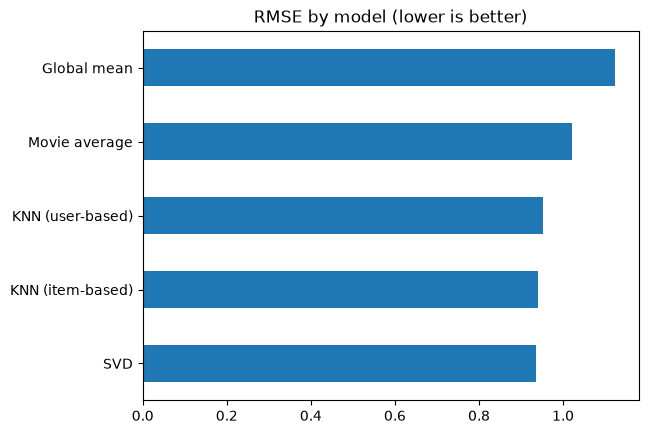

In [12]:
import matplotlib.pyplot as plt
all_rmse = {"Global mean": rmse(test.rating, [global_mean]*len(test)),
            "Movie average": rmse(test.rating, pred), **results}
pd.Series(all_rmse).sort_values().plot(kind="barh", title="RMSE by model (lower is better)")
plt.show()

In [13]:
movies = pd.read_csv("data/ml-100k/u.item", sep="|", encoding="latin-1", usecols=[0, 1], names=["item_id", "title"])
best = models["SVD"]

def recommend(user_id, n=10):
    seen = set(train[train.user_id == user_id].item_id)
    candidates = [i for i in movies.item_id if i not in seen]
    scored = sorted(((best.predict(user_id, i).est, i) for i in candidates), reverse=True)[:n]
    return movies.set_index("item_id").loc[[i for _, i in scored]].assign(predicted=[round(s, 2) for s, _ in scored])

recommend(1)

,title,predicted
item_id,,
285,Secrets & Lies (1996),4.96
100,Fargo (1996),4.94
474,Dr. Strangelove or: How I Learned to Stop Worr...,4.87
408,"Close Shave, A (1995)",4.80
513,"Third Man, The (1949)",4.73
657,"Manchurian Candidate, The (1962)",4.71
745,"Ruling Class, The (1972)",4.70
483,Casablanca (1942),4.69
8,Babe (1995),4.69


In [14]:
import joblib
joblib.dump(best, "data/svd_model.pkl")

['data/svd_model.pkl']